**Extract a clean CSV**

In [7]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt



**Three VAR Methods and Expected Shortfall**

In [8]:
df = pd.read_csv("data/sp500_2000_2008.csv", index_col="Date", parse_dates=True)
r = df["Returns"].dropna()
S0 = df["Adjusted close"].iloc[-1]
pos = 1000 * S0
alpha = 0.99
z = stats.norm.ppf(alpha)
mu, sd = r.mean(), r.std()

var_dn = (z*sd - mu) * pos
var_hs = -np.percentile(r, 100*(1-alpha)) * pos
sims = np.random.default_rng(42).normal(mu, sd, 50_000)
var_mc = -np.percentile(sims, 100*(1-alpha)) * pos

es_dn = (sd*stats.norm.pdf(z)/(1-alpha) - mu) * pos
q = np.percentile(r, 100*(1-alpha));   es_hs = -r[r <= q].mean() * pos
qm = np.percentile(sims, 100*(1-alpha)); es_mc = -sims[sims <= qm].mean() * pos

tab = pd.DataFrame({"VaR 1d": [var_dn, var_hs, var_mc], "ES 1d": [es_dn, es_hs, es_mc]},
                   index=["Delta-Normal", "Historical", "Monte Carlo"])
tab["VaR 10d"] = tab["VaR 1d"] * np.sqrt(10)
tab["ES 10d"] = tab["ES 1d"] * np.sqrt(10)
print(tab.round(0))

               VaR 1d    ES 1d   VaR 10d    ES 10d
Delta-Normal  36135.0  41394.0  114268.0  130898.0
Historical    41130.0  50412.0  130066.0  159417.0
Monte Carlo   36296.0  41604.0  114778.0  131563.0


**rolling backtest, Kupiec test, Basel zones**

Method  Days  Exceptions  Expected  Kupiec LR  p-value Decision (5%)  Exc last 250d Basel zone
    HS   759          17       7.6       8.72    0.003        reject             10        red
    DN   759          24       7.6      22.80    0.000        reject             17        red


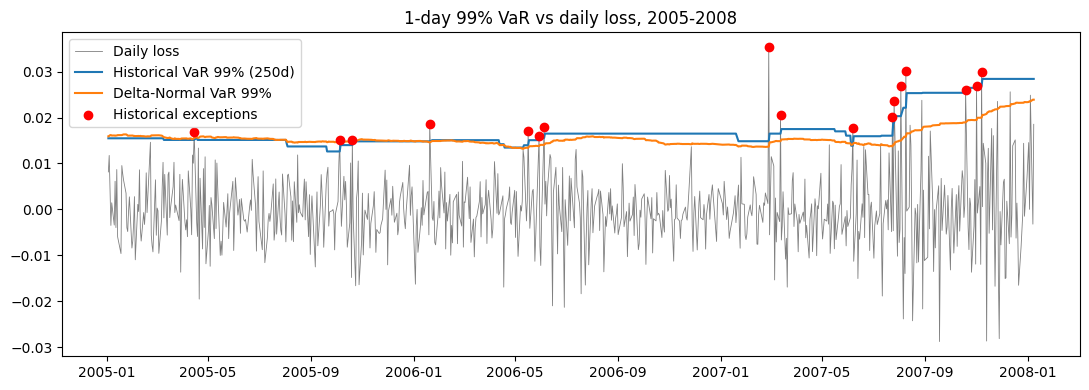

In [9]:
WINDOW = 250
hs  = -r.rolling(WINDOW).quantile(1-alpha).shift(1)                    # VaR known the day before
dn  = z*r.rolling(WINDOW).std().shift(1) - r.rolling(WINDOW).mean().shift(1)
bt = pd.DataFrame({"ret": r, "HS": hs, "DN": dn}).dropna().loc["2005-01-01":]
bt["loss"] = -bt["ret"]
bt["exc_HS"] = bt["loss"] > bt["HS"]
bt["exc_DN"] = bt["loss"] > bt["DN"]

def kupiec(x, n, p=1-alpha):
    ph = x/n
    lr = -2*((n-x)*np.log(1-p) + x*np.log(p) - (n-x)*np.log(1-ph) - x*np.log(ph))
    return lr, 1 - stats.chi2.cdf(lr, 1)

def zone(x): return "green" if x <= 4 else ("yellow" if x <= 9 else "red")   # Basel, 250 obs, 99%

rows = []
for m in ["HS", "DN"]:
    x, n = int(bt[f"exc_{m}"].sum()), len(bt)
    lr, pv = kupiec(x, n)
    x250 = int(bt.tail(250)[f"exc_{m}"].sum())
    rows.append([m, n, x, round(n*(1-alpha), 1), round(lr, 2), round(pv, 3),
                 "reject" if pv < 0.05 else "do not reject", x250, zone(x250)])
print(pd.DataFrame(rows, columns=["Method","Days","Exceptions","Expected","Kupiec LR","p-value","Decision (5%)","Exc last 250d","Basel zone"]).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(bt.index, bt["loss"], lw=0.6, color="grey", label="Daily loss")
ax.plot(bt.index, bt["HS"], color="tab:blue", label="Historical VaR 99% (250d)")
ax.plot(bt.index, bt["DN"], color="tab:orange", label="Delta-Normal VaR 99%")
ex = bt[bt["exc_HS"]]
ax.scatter(ex.index, ex["loss"], color="red", zorder=3, label="Historical exceptions")
ax.set_title("1-day 99% VaR vs daily loss, 2005-2008"); ax.legend(); plt.tight_layout(); plt.savefig("backtest.png", dpi=120); plt.show()

**stress scenarios on the index position**

In [10]:
loss1 = -r * pos
r10 = np.log(df["Adjusted close"]).diff(10).dropna()
st = pd.Series({
  "Worst 1-day loss in sample": loss1.max(),
  "Worst 10-day loss in sample": (-r10*pos).max(),
  "Shock -5% index": 0.05*pos, "Shock -10% index": 0.10*pos, "Shock -20% index": 0.20*pos,
  "Vol x2 (Delta-Normal 1d VaR)": (z*2*sd - mu)*pos})
print(st.round(0))
print("worst day:", r.idxmin().date(), round(r.min(), 4), "| worst 10d window ends:", r10.idxmin().date(), round(r10.min(), 4))

Worst 1-day loss in sample       83474.0
Worst 10-day loss in sample     247042.0
Shock -5% index                  69510.0
Shock -10% index                139019.0
Shock -20% index                278038.0
Vol x2 (Delta-Normal 1d VaR)     72238.0
dtype: float64
worst day: 2000-04-14 -0.06 | worst 10d window ends: 2002-07-23 -0.1777


**Options position (short ATM straddle) and why Delta-Normal fails**

In [11]:
def bs(S, K, T, rf, sig, kind):
    d1 = (np.log(S/K) + (rf + 0.5*sig**2)*T)/(sig*np.sqrt(T)); d2 = d1 - sig*np.sqrt(T)
    return S*stats.norm.cdf(d1) - K*np.exp(-rf*T)*stats.norm.cdf(d2) if kind == "call" \
           else K*np.exp(-rf*T)*stats.norm.cdf(-d2) - S*stats.norm.cdf(-d1)
def delta(S, K, T, rf, sig, kind):
    d1 = (np.log(S/K) + (rf + 0.5*sig**2)*T)/(sig*np.sqrt(T))
    return stats.norm.cdf(d1) if kind == "call" else stats.norm.cdf(d1) - 1

K, T, rf, units = round(S0), 30/365, 0.04, 1000      # assumptions: ATM, 30 days, 4% rate
sig = sd*np.sqrt(252)                                 # realised vol as the pricing vol
val0 = units*(bs(S0,K,T,rf,sig,"call") + bs(S0,K,T,rf,sig,"put"))

S_scen = S0*np.exp(r.values)                          # revalue under every historical 1-day return
val1 = units*(bs(S_scen,K,T-1/252,rf,sig,"call") + bs(S_scen,K,T-1/252,rf,sig,"put"))
pnl = -(val1 - val0)                                  # we are short the straddle
var_full = -np.percentile(pnl, 1)
es_full = -pnl[pnl <= np.percentile(pnl, 1)].mean()

d_net = -units*(delta(S0,K,T,rf,sig,"call") + delta(S0,K,T,rf,sig,"put"))
var_delta = abs(d_net)*S0*z*sd

print(f"vol={sig:.3f} strike={K} premium={val0:,.0f} net delta={d_net:,.0f} index units")
print(f"Delta-Normal 1d VaR:        {var_delta:,.0f}")
print(f"Full-revaluation 1d VaR:    {var_full:,.0f}   ES: {es_full:,.0f}")
for s in [-0.10, -0.05, 0.05, 0.10]:
    S1 = S0*(1+s); v = units*(bs(S1,K,T,rf,sig,"call") + bs(S1,K,T,rf,sig,"put"))
    print(f"Index {s:+.0%}: P&L {-(v-val0):,.0f}")
for vs in [1.5, 2.0]:
    v = units*(bs(S0,K,T,rf,sig*vs,"call") + bs(S0,K,T,rf,sig*vs,"put"))
    print(f"Vol x{vs}: P&L {-(v-val0):,.0f}")

vol=0.177 strike=1390 premium=56,379 net delta=-74 index units
Delta-Normal 1d VaR:        2,669
Full-revaluation 1d VaR:    14,318   ES: 20,775
Index -10%: P&L -79,004
Index -5%: P&L -21,144
Index +5%: P&L -29,297
Index +10%: P&L -88,851
Vol x1.5: P&L -28,072
Vol x2.0: P&L -56,151
